In [22]:
#import des package necessaire pour le postprocess
#imp est le package que j'ai développé pour rendre le postprocessing plus facile et automatique

from astropy.io import fits
import glob, os
import numpy as np
import matplotlib.pyplot as plt

import imodex_miri_postprocess_pipeline as imp

Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 1 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 9 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
Loading of 2 cubes.
Number of dimension : 2
Initial images size (px) : 288 / 224
New images size (px)     : 200 / 200
sigma model PSF:  1.3965812874037857
152 156
Roll - TA 1
Result : A = 16917.5 / x0 = 155.97 / y0 = 151.65 / width_x = 1.58 / width_y = 1.55
Stddev : A = 26.4 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
113 112
Roll - TA 2
Result : A = 17043.4 / x0 = 112.44 / y0 = 112.56 / width_x = 1.58 / width_y = 1.54
Stddev : A = 25.1 / x0 = 0.0 / y0 = 0.0 / width_x = 0.0 / width_y = 0.0
Loading of 2 cubes.
Num

/home/cperrot/anaconda3/envs/mirisim/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1218: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,


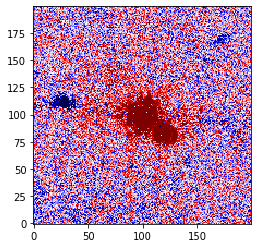

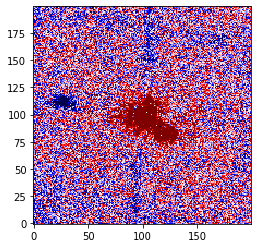

In [23]:
#Definition des path pour accéder aux raw, au code et au dossier de stockage des produits
path_raw    = "/home/cperrot/Work/raw/JWST/Target/MAST/CAL/P01194/"
path_bkgPCA = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1550C/PCA/"
path_save   = "/home/cperrot/Work/projet/JWST/Target/backgrounds/F1550C/PCA/"



### PCA background
bkgPCA_sci = fits.open(path_bkgPCA+"PCA_background_P01194_obs011_F1550C.fits")[0].data
bkgPCA_ref = fits.open(path_bkgPCA+"PCA_background_P01194_obs018_F1550C.fits")[0].data

### MAST background
bkg_sci, bkg_sci_h = imp.load_cube(path_raw+'obs011/', '_cal', xdim=200, ydim=200, x0=120, y0=114)
bkg_ref, bkg_ref_h = imp.load_cube(path_raw+'obs018/', '_cal', xdim=200, ydim=200, x0=120, y0=114)

bkg_sci = np.minimum(bkg_sci[0],bkg_sci[1])
bkg_ref = np.minimum(bkg_ref[0],bkg_ref[1])



### SCI without backgroud subtraction
sci, sci_h = imp.load_cube(path_raw+'obs009/', '_cal', xdim=200, ydim=200, x0=120, y0=114)

### REF without background subtraction
ref, ref_h = imp.load_cube(path_raw+'obs016/', '_cal', xdim=200, ydim=200, x0=120, y0=114)

sci_clean = sci - bkgPCA_sci
ref_clean = ref - bkgPCA_ref

f_scale = imp.flux_scaling_ta(path_raw+'obs009/TA/', path_raw+'obs016/TA/', '_cal', 11.40e-6)
RDI_pca = imp.RDI_classic(sci_clean, ref_clean, f_scale=f_scale)
RDI     = imp.RDI_classic(sci - bkg_sci, ref - bkg_ref, f_scale=f_scale)

plt.imshow(RDI,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()
plt.imshow(RDI_pca,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()

imp.save_fits(RDI,path_save+'RDI_HR8799_F1550C_original-bkg.fits')
imp.save_fits(RDI_pca,path_save+'RDI_HR8799_F1550C_PCA-bkg.fits')


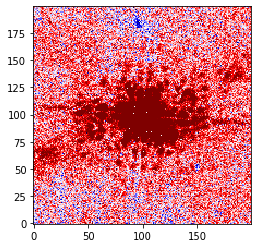

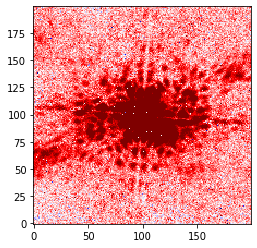

In [24]:
plt.imshow(sci-bkgPCA_sci,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()
plt.imshow(sci-bkg_sci,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()


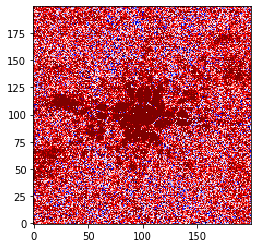

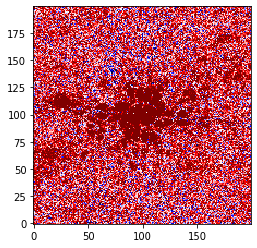

In [25]:
plt.imshow(ref[0]-bkgPCA_ref,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()
plt.imshow(ref[0]-bkg_ref,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()


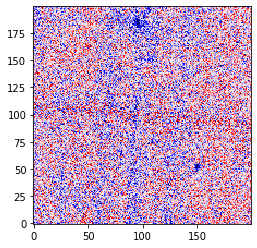

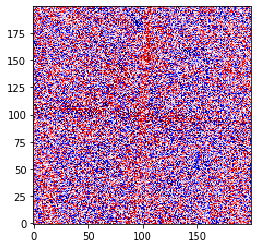

In [26]:
plt.imshow(bkg_sci-bkgPCA_sci,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()
plt.imshow(bkg_ref-bkgPCA_ref,origin='lower',interpolation='none',cmap='seismic',vmin=-1,vmax=1)
plt.show()


In [30]:
cst_std_pca = []
cst_med_pca = []
cst_moy_pca = []
cst_std = []
cst_med = []
cst_moy = []

copy_RDI     = RDI.copy() #copie de l'image RDI roll 2
copy_RDI_pca = RDI_pca.copy() #copie de l'image RDI roll 2

copy_RDI     = imp.sigma_clip_jwst(copy_RDI, sig=3)
copy_RDI_pca = imp.sigma_clip_jwst(copy_RDI_pca, sig=3)

copy_RDI     = imp.clean_image_nan(copy_RDI)
copy_RDI_pca = imp.clean_image_nan(copy_RDI_pca)

imp.save_fits(copy_RDI,path_save+'RDI_HR8799_F1550C_clean_original-bkg.fits')
imp.save_fits(copy_RDI_pca,path_save+'RDI_HR8799_F1550C_clean_PCA-bkg.fits')


mask = np.concatenate([np.arange(-99.5,0.5,1)*(-1),np.arange(0.5,100.5,1)])
mask = np.sqrt(mask**2+mask[:,np.newaxis]**2)

for i in np.arange(2,141,2):
    cst_med_pca.append(np.nanmedian(copy_RDI_pca[(mask>i-2) & (mask<=i)]))
    cst_moy_pca.append(np.nanmean(copy_RDI_pca[(mask>i-2) & (mask<=i)]))
    cst_std_pca.append(np.nanstd(copy_RDI_pca[(mask>i-2) & (mask<=i)]))
    
    cst_med.append(np.nanmedian(copy_RDI[(mask>i-2) & (mask<=i)]))
    cst_moy.append(np.nanmean(copy_RDI[(mask>i-2) & (mask<=i)]))
    cst_std.append(np.nanstd(copy_RDI[(mask>i-2) & (mask<=i)]))
    
fig=plt.figure(figsize=(8,8))
plt.plot(np.arange(1,140,2)*0.110,cst_moy_pca,color='red',label='PCA')
plt.plot(np.arange(1,140,2)*0.110,cst_moy,color='blue',label='Original')
plt.title('Mean')
plt.yscale('log')
plt.xlabel('Separation (arcsec)')
plt.legend(loc='upper right',fontsize='small')
#plt.ylim(1e-1,1e2)
fig.savefig(path_save+'RDI_HR8799_F1550C_radial_profile_mean.pdf',format='pdf',bbox_inches='tight')
plt.close(fig)

fig=plt.figure(figsize=(8,8))
plt.plot(np.arange(1,140,2)*0.110,cst_med_pca,color='red',label='PCA')
plt.plot(np.arange(1,140,2)*0.110,cst_med,color='blue',label='Original')
plt.title('Median')
plt.yscale('log')
plt.xlabel('Separation (arcsec)')
plt.legend(loc='upper right',fontsize='small')
#plt.ylim(1e-1,1e2)
fig.savefig(path_save+'RDI_HR8799_F1550C_radial_profile_median.pdf',format='pdf',bbox_inches='tight')
plt.close(fig)

fig=plt.figure(figsize=(8,8))
plt.plot(np.arange(1,140,2)*0.110,cst_std_pca,color='red',label='PCA')
plt.plot(np.arange(1,140,2)*0.110,cst_std,color='blue',label='Original')
plt.title('Standard Deviation')
plt.yscale('log')
plt.xlabel('Separation (arcsec)')
plt.legend(loc='upper right',fontsize='small')
plt.ylim(1e-1,1e1)
fig.savefig(path_save+'RDI_HR8799_F1550C_radial_profile_stddev.png',format='png',bbox_inches='tight')
plt.close(fig)